# Supermarket Sales: Exploratory Data Analysis
**Course:** MIS 311 – Introduction to Business Analytics  |  **Tools:** Python (pandas, matplotlib, seaborn)

**Business question:** Where does revenue come from, and which customer or store segments deserve attention?

Sections: 1. Data Overview, 2. Data Cleaning, 3. Descriptive Statistics and Key Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
os.makedirs("images", exist_ok=True)
os.makedirs("data", exist_ok=True)

## 1. Data Overview

In [2]:
df_raw = pd.read_excel("data/10_Supermarket Sale.xlsx")
print("Rows x Columns:", df_raw.shape)
df_raw.head()

Rows x Columns: (253, 8)


,sale_id,branch,city,customer_type,product_name,product_category,quantity,total_price
0,1,A,New York,Member,Shampoo,Personal Care,3.0,17.66
1,2,B,Los Angeles,Normal,Notebook,Stationery,10.0,29.43
2,3,A,New York,Member,Apple,Fruits,15.0,19.26
3,4,A,Chicago,Normal,Detergent,Household,5.0,41.73
4,5,B,Los Angeles,Member,Orange Juice,Beverages,7.0,26.22


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sale_id           253 non-null    int64  
 1   branch            253 non-null    str    
 2   city              253 non-null    str    
 3   customer_type     250 non-null    str    
 4   product_name      253 non-null    str    
 5   product_category  247 non-null    str    
 6   quantity          250 non-null    float64
 7   total_price       253 non-null    float64
dtypes: float64(2), int64(1), str(5)
memory usage: 15.9 KB


**Dataset description**

| Item | Detail |
|---|---|
| Source | Datasets for Assessment, MIS 311 (EIU), file `10_Supermarket Sale.xlsx` |
| Size | 253 rows x 8 columns |
| Context | Transaction-level sales records from a supermarket chain with 2 branches and 3 cities |
| Columns | `sale_id`, `branch`, `city`, `customer_type`, `product_name`, `product_category`, `quantity`, `total_price` |

Each row is one sale. `total_price` is the revenue of the sale (currency not stated; assumed USD) and `quantity` is the number of units sold.

## 2. Data Cleaning

### 2.1 Missing values

In [4]:
missing = df_raw.isnull().sum()
missing[missing > 0].to_frame("missing_count").assign(pct=lambda x: (x.missing_count / len(df_raw) * 100).round(2))

,missing_count,pct
customer_type,3,1.19
product_category,6,2.37
quantity,3,1.19


Only 3 columns have gaps (12 cells in total, under 2.5% of rows each). Before choosing a method, check whether `product_category` can be recovered from `product_name`.

In [5]:
pd.crosstab(df_raw["product_name"], df_raw["product_category"])

product_category,Beverages,Fruits,Household,Personal Care,Stationery
product_name,,,,,
Apple,10,12,7,6,7
Detergent,6,7,12,8,9
Notebook,14,13,10,7,10
Orange Juice,8,11,14,9,7
Shampoo,9,17,12,11,11


**Finding:** every product appears under *every* category (e.g. Shampoo is labelled Fruits 17 times). So `product_category` is **not reliably determined by `product_name`**, and it cannot be recovered from it. This is a data-quality issue that I will keep in mind when interpreting category results.

**Decisions**

| Column | Missing | Method | Reason |
|---|---|---|---|
| `customer_type` | 3 | Fill with `"Unknown"` | Categorical, cannot be inferred; keeps the sales revenue |
| `product_category` | 6 | Fill with `"Unknown"` | Cannot be inferred from product (see above) |
| `quantity` | 3 | Fill with the **median** | Numeric, bounded 1–20; median is robust and `total_price` is complete |

### 2.2 Duplicate rows

In [6]:
print("Duplicate rows:", df_raw.duplicated().sum())
df_raw[df_raw.duplicated(keep=False)].sort_values("sale_id")

Duplicate rows: 3


,sale_id,branch,city,customer_type,product_name,product_category,quantity,total_price
11,13,A,New York,Normal,Orange Juice,Household,4.0,14.08
13,13,A,New York,Normal,Orange Juice,Household,4.0,14.08
26,26,B,Los Angeles,Normal,Notebook,Fruits,16.0,238.65
27,26,B,Los Angeles,Normal,Notebook,Fruits,16.0,238.65
40,40,A,New York,Normal,Apple,Fruits,11.0,13.77
42,40,A,New York,Normal,Apple,Fruits,11.0,13.77


All three duplicates are exact copies of the whole row (same `sale_id` and values), i.e. the same sale recorded twice. Keeping them would double count revenue, so they are removed.

In [7]:
df = df_raw.drop_duplicates().copy()

df["customer_type"] = df["customer_type"].fillna("Unknown")
df["product_category"] = df["product_category"].fillna("Unknown")
df["quantity"] = df["quantity"].fillna(df["quantity"].median())

print("Rows before:", len(df_raw), "| after:", len(df))
print("Remaining missing values:", int(df.isnull().sum().sum()))
print("Duplicate sale_id left:", int(df["sale_id"].duplicated().sum()))
df.to_csv("data/supermarket_cleaned.csv", index=False)

Rows before: 253 | after: 250
Remaining missing values: 0
Duplicate sale_id left: 0


### 2.3 Sanity checks

In [8]:
df["unit_price"] = df["total_price"] / df["quantity"]
print("Quantity range:", df["quantity"].min(), "-", df["quantity"].max())
print("Total price range:", df["total_price"].min(), "-", df["total_price"].max())
print("Unit price range:", round(df["unit_price"].min(), 2), "-", round(df["unit_price"].max(), 2))
print("\nBranch vs city:")
print(pd.crosstab(df["branch"], df["city"]))

Quantity range: 1.0 - 20.0
Total price range: 2.18 - 427.14
Unit price range: 1.09 - 22.37

Branch vs city:
city    Chicago  Los Angeles  New York
branch                                
A            77            0        95
B             0           78         0


Values are all plausible (no negatives or impossible numbers). Note that Branch B exists only in Los Angeles, and Branch A covers New York and Chicago, so branch and city are overlapping dimensions. I analyse **city** to avoid mixing them up.

## 3. Descriptive Statistics

In [9]:
df[["quantity", "total_price"]].describe().round(2)

,quantity,total_price
count,250.00,250.00
mean,10.62,124.19
std,5.99,102.98
min,1.00,2.18
25%,5.00,40.89
50%,11.00,95.43
75%,16.00,194.94
max,20.00,427.14


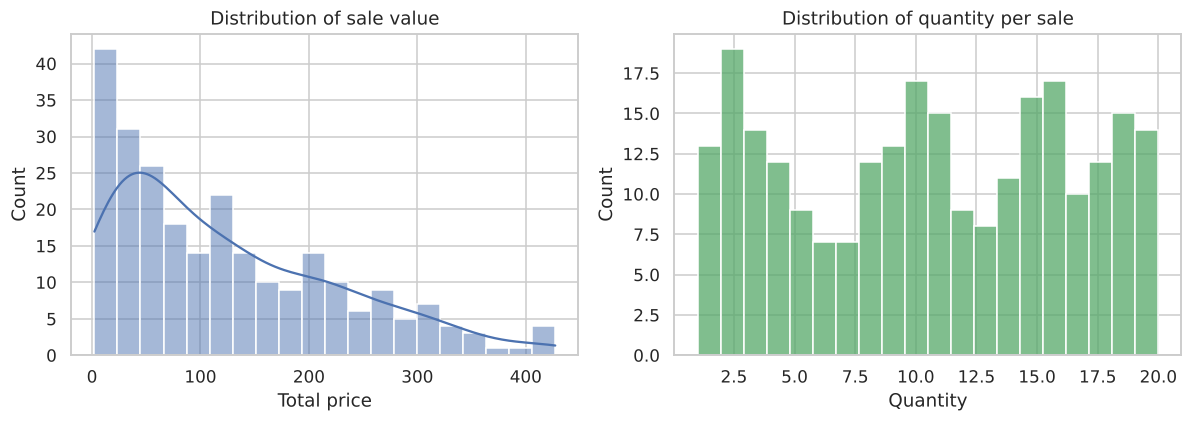

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["total_price"], bins=20, kde=True, ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribution of sale value")
ax[0].set_xlabel("Total price")
sns.histplot(df["quantity"], bins=20, ax=ax[1], color="#55A868")
ax[1].set_title("Distribution of quantity per sale")
ax[1].set_xlabel("Quantity")
plt.tight_layout()
plt.savefig("images/01_distributions.png", bbox_inches="tight")
plt.show()

In [11]:
for col in ["city", "customer_type", "product_name", "product_category"]:
    print(f"--- {col} ---")
    print(df[col].value_counts().to_string(), "\n")

--- city ---
city
New York       95
Los Angeles    78
Chicago        77 

--- customer_type ---
customer_type
Member     131
Normal     116
Unknown      3 

--- product_name ---
product_name
Shampoo         61
Notebook        53
Orange Juice    50
Detergent       45
Apple           41 

--- product_category ---
product_category
Fruits           58
Household        54
Beverages        47
Stationery       44
Personal Care    41
Unknown           6 



In [12]:
print("Total revenue:", round(df["total_price"].sum(), 2))
print("Mean sale:", round(df["total_price"].mean(), 2), "| Median sale:", round(df["total_price"].median(), 2))
print("Correlation quantity vs total_price:", round(df["quantity"].corr(df["total_price"]), 3))

Total revenue: 31046.28
Mean sale: 124.19 | Median sale: 95.43
Correlation quantity vs total_price: 0.722


### Insight 1: Member customers spend more per sale than Normal customers

,count,total,mean,median,pct_of_revenue
customer_type,,,,,
Member,131,17855.87,136.30,115.56,57.7
Normal,116,13106.73,112.99,79.33,42.3


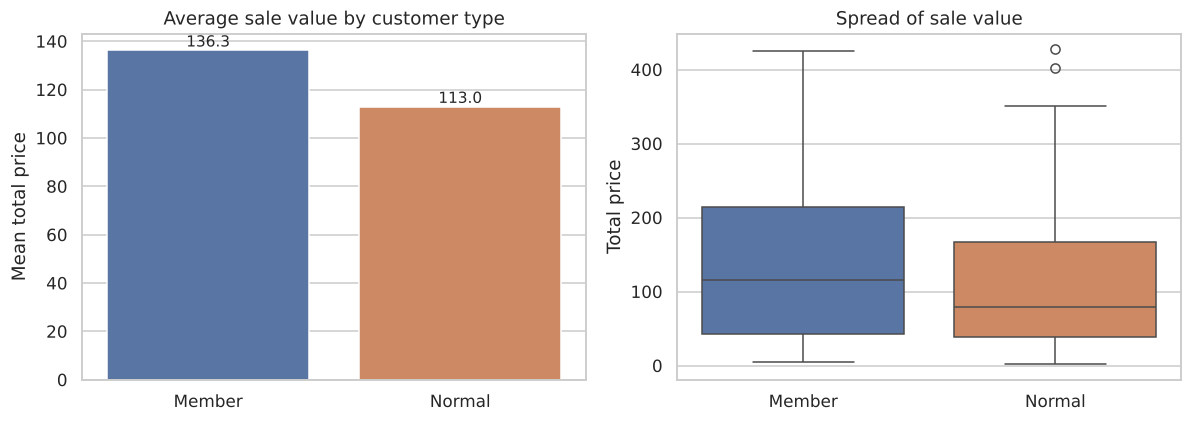

In [13]:
known = df[df["customer_type"] != "Unknown"]
ct = known.groupby("customer_type")["total_price"].agg(count="count", total="sum", mean="mean", median="median").round(2)
ct["pct_of_revenue"] = (ct["total"] / ct["total"].sum() * 100).round(1)
display(ct)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=known, x="customer_type", y="total_price", estimator="mean", errorbar=None,
            order=["Member", "Normal"], ax=ax[0], hue="customer_type", legend=False)
ax[0].set_title("Average sale value by customer type")
ax[0].set_xlabel(""); ax[0].set_ylabel("Mean total price")
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)
sns.boxplot(data=known, x="customer_type", y="total_price", order=["Member", "Normal"],
            ax=ax[1], hue="customer_type", legend=False)
ax[1].set_title("Spread of sale value")
ax[1].set_xlabel(""); ax[1].set_ylabel("Total price")
plt.tight_layout()
plt.savefig("images/02_customer_type.png", bbox_inches="tight")
plt.show()

In [14]:
# Is the gap explained by basket size? Compare average quantity too.
print(known.groupby("customer_type")[["quantity", "unit_price"]].mean().round(2))

               quantity  unit_price
customer_type                      
Member            11.15       12.05
Normal            10.16       11.25


In [15]:
from scipy import stats
m = known[known["customer_type"] == "Member"]["total_price"]
n = known[known["customer_type"] == "Normal"]["total_price"]
print("Member vs Normal, Welch t-test p-value:", round(stats.ttest_ind(m, n, equal_var=False).pvalue, 3))

Member vs Normal, Welch t-test p-value: 0.074


**Caution:** p is about 0.07, so the gap is *suggestive* but not statistically conclusive at the usual 5% level with this sample size. I treat it as a lead to investigate, not a proven effect.

### Insight 2: Chicago earns the most revenue with the fewest transactions, thanks to a higher average sale

,transactions,total,mean,pct_of_revenue
city,,,,
Chicago,77,11133.05,144.59,35.9
New York,95,10964.42,115.41,35.3
Los Angeles,78,8948.81,114.73,28.8


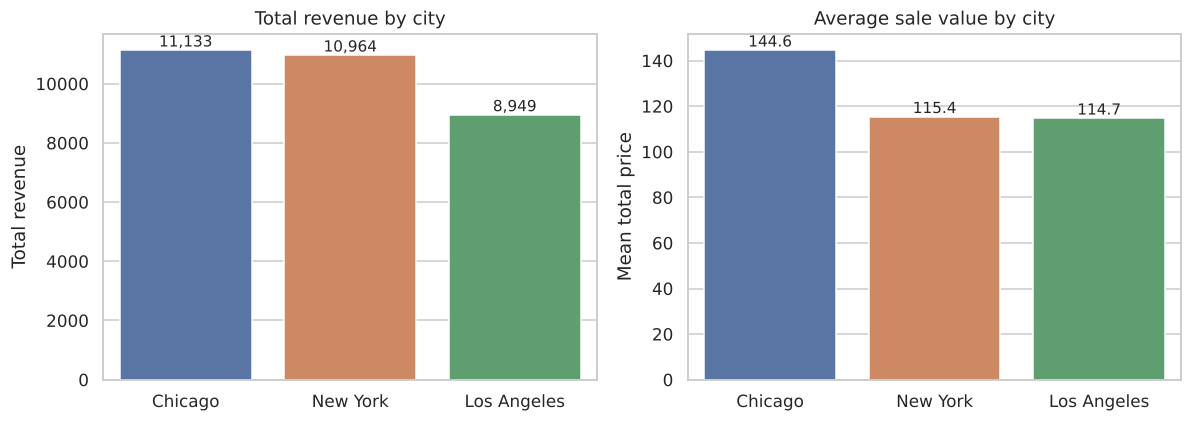

In [16]:
city = df.groupby("city")["total_price"].agg(transactions="count", total="sum", mean="mean").round(2)
city["pct_of_revenue"] = (city["total"] / city["total"].sum() * 100).round(1)
city = city.sort_values("total", ascending=False)
display(city)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=city.index, y=city["total"], ax=ax[0], hue=city.index, legend=False)
ax[0].set_title("Total revenue by city"); ax[0].set_xlabel(""); ax[0].set_ylabel("Total revenue")
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)
sns.barplot(x=city.index, y=city["mean"], ax=ax[1], hue=city.index, legend=False)
ax[1].set_title("Average sale value by city"); ax[1].set_xlabel(""); ax[1].set_ylabel("Mean total price")
for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig("images/03_city.png", bbox_inches="tight")
plt.show()

In [17]:
# Why is Chicago's average higher? Check quantity per sale.
print(df.groupby("city")[["quantity", "unit_price"]].mean().round(2))

             quantity  unit_price
city                             
Chicago         11.32       12.31
Los Angeles     10.85       10.83
New York         9.85       11.72


In [18]:
ch = df[df["city"] == "Chicago"]["total_price"]
other = df[df["city"] != "Chicago"]["total_price"]
print("Chicago vs other cities, Welch t-test p-value:", round(stats.ttest_ind(ch, other, equal_var=False).pvalue, 3))

Chicago vs other cities, Welch t-test p-value: 0.052


**Caution:** p is about 0.05, so Chicago's higher average is borderline. The solid facts are the totals: Chicago leads revenue (35.9%) with only 77 transactions, while New York has the most transactions (95) but a lower average sale. Whether Chicago's per-sale edge is real is a lead to verify.